
# AURORA cfDNA Regional Fragmentation Analysis  
## Step 1: QC, treatment-context merge, cytoband annotation, chromosome/arm summaries

This notebook is organized as **one code cell per major step** so you can run and monitor the analysis in real time.

This notebook does **not** perform association modeling yet.  
The goal is to prepare the regional fragmentation dataset for downstream modeling.

### Major steps

1. Setup paths, parameters, and helper functions  
2. Load regional matrix and parse genomic bins  
3. Load clinical annotation and map treatment context  
4. Merge regional samples with clinical annotation and define analysis-ready cohort  
5. Load cytoband and annotate bins with chromosome arm  
6. Create retained sample × bin matrix and QC summaries  
7. Create chromosome-level and chromosome-arm-level summaries  
8. Generate Step 1 QC plots  
9. Save Step 1 scientific notes  


In [4]:

# ============================================================
# STEP 1: Setup paths, parameters, and helper functions
# ============================================================

from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Notebook started:", time.ctime())

REGIONAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
)

CLINICAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

CYTOBAND = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/"
    "Human_ref_hg38_p7/cytoBand.txt"
)

OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

TABLE_DIR = OUT_DIR / "Step1_QC_tables"
PLOT_DIR = OUT_DIR / "Step1_QC_plots"

for d in [OUT_DIR, TABLE_DIR, PLOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TREATMENT_ORDER = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment",
]

TFX_COL = "Tumor_Fraction_percent_from_CNV_annotation"

AUTOSOMES_ONLY = True
CREATE_SAMPLE_CENTERED_VERSION = True

for p in [REGIONAL_FILE, CLINICAL_FILE, CYTOBAND]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")
    print("Found:", p)

print("\nOutput table directory:", TABLE_DIR)
print("Output plot directory:", PLOT_DIR)


def clean_barcode(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip()


def chrom_sort_key(chrom):
    chrom = str(chrom).replace("chr", "")
    if chrom.isdigit():
        return int(chrom)
    if chrom == "X":
        return 23
    if chrom == "Y":
        return 24
    if chrom in ["M", "MT"]:
        return 25
    return 999


BIN_PATTERNS = [
    re.compile(r"^(chr(?:[0-9]{1,2}|X|Y|M|MT))[_:](\d+)[_-](\d+)$"),
    re.compile(r"^(chr(?:[0-9]{1,2}|X|Y|M|MT))[_-](\d+)[_-](\d+)$"),
]


def parse_bin_name(bin_name):
    """
    Parse names like:
      chr1_100000_200000
      chr1:100000-200000
      chr1-100000-200000
    """
    s = str(bin_name)
    for pat in BIN_PATTERNS:
        m = pat.match(s)
        if m:
            return m.group(1), int(m.group(2)), int(m.group(3))
    return None, np.nan, np.nan


def map_treatment_context(x):
    """
    Map Treatment_context_at_draw to the same 3 groups used in global analysis.
    """
    if pd.isna(x):
        return np.nan, "missing"

    s = str(x).strip()

    if s == "Pre-treatment":
        return "Pre-treatment", "mapped_pre"

    if s == "On-treatment":
        return "On-treatment", "mapped_on"

    if s in ["Post-treatment", "Between-treatment-lines"]:
        return "Post-treatment/off-treatment", "mapped_post_off"

    if s in [
        "No matched treatment context",
        "No clinical blood draw date or patient_id mapping",
    ]:
        return np.nan, "excluded_missing_or_ambiguous_treatment_context"

    return np.nan, "unmapped_value_review_needed"


def assign_bin_to_cytoband(bin_df, cytoband_df):
    """
    Assign each bin to a cytoband and chromosome arm using bin midpoint.
    """
    out_list = []

    cytoband_by_chr = {
        chrom: sub.sort_values("start").reset_index(drop=True)
        for chrom, sub in cytoband_df.groupby("chrom")
    }

    for _, row in bin_df.iterrows():
        chrom = row["chrom"]
        mid = row["midpoint"]

        band = np.nan
        stain = np.nan
        arm = np.nan
        chrom_arm = np.nan

        if chrom in cytoband_by_chr and pd.notna(mid):
            sub = cytoband_by_chr[chrom]
            hit = sub[(sub["start"] <= mid) & (sub["end"] > mid)]

            if hit.shape[0] > 0:
                band = hit.iloc[0]["band"]
                stain = hit.iloc[0]["stain"]

                if str(band).startswith("p"):
                    arm = "p"
                elif str(band).startswith("q"):
                    arm = "q"

                if arm in ["p", "q"]:
                    chrom_arm = f"{chrom}{arm}"

        out_list.append({
            "bin": row["bin"],
            "chrom": chrom,
            "start": row["start"],
            "end": row["end"],
            "midpoint": mid,
            "cytoband": band,
            "cytoband_stain": stain,
            "arm": arm,
            "chrom_arm": chrom_arm,
            "chrom_order": chrom_sort_key(chrom),
        })

    return pd.DataFrame(out_list)


def summarize_matrix_by_group(X, bin_annot, group_col):
    """
    Summarize sample x bin matrix into sample x chromosome or sample x arm matrix.
    """
    groups = (
        bin_annot[[group_col, "bin"]]
        .dropna()
        .groupby(group_col)["bin"]
        .apply(list)
        .to_dict()
    )

    out = pd.DataFrame(index=X.index)

    def group_sort_key(g):
        g = str(g)
        chrom_part = g
        arm_part = ""
        if g.endswith("p") or g.endswith("q"):
            chrom_part = g[:-1]
            arm_part = g[-1]
        return (chrom_sort_key(chrom_part), arm_part)

    for g in sorted(groups.keys(), key=group_sort_key):
        cols = [c for c in groups[g] if c in X.columns]
        if len(cols) == 0:
            continue
        out[g] = X[cols].mean(axis=1, skipna=True)

    return out


def save_barplot_counts(series, path, title, xlabel="", ylabel="Number of blood draws"):
    counts = series.value_counts().reindex(TREATMENT_ORDER).dropna()

    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(counts.index.astype(str), counts.values)

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            str(int(h)),
            ha="center",
            va="bottom",
            fontsize=10,
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def save_boxplot_by_context(df, value_col, path, title, ylabel):
    plot_df = df.dropna(subset=["Treatment_Context_3group", value_col]).copy()
    plot_df["Treatment_Context_3group"] = pd.Categorical(
        plot_df["Treatment_Context_3group"],
        categories=TREATMENT_ORDER,
        ordered=True,
    )

    groups = [
        plot_df.loc[plot_df["Treatment_Context_3group"].eq(g), value_col].values
        for g in TREATMENT_ORDER
    ]

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.boxplot(groups, labels=TREATMENT_ORDER, showfliers=False)

    rng = np.random.default_rng(123)
    for i, vals in enumerate(groups, start=1):
        x = rng.normal(i, 0.04, size=len(vals))
        ax.scatter(x, vals, s=12, alpha=0.5)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


Notebook started: Sun Jun 14 21:36:27 2026
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx
Found: /ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/Human_ref_hg38_p7/cytoBand.txt

Output table directory: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables
Output plot directory: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_plots


In [5]:

# ============================================================
# STEP 2: Load regional matrix and parse genomic bins
# ============================================================

regional = pd.read_csv(REGIONAL_FILE, low_memory=False)

print("Raw regional matrix shape:", regional.shape)
print("First 10 columns:")
display(pd.DataFrame({"columns": regional.columns[:10]}))

sample_col = regional.columns[0]
print("Using first column as sample barcode column:", sample_col)

regional = regional.rename(columns={sample_col: "Barcode"})
regional["Barcode"] = regional["Barcode"].apply(clean_barcode)

print("Unique regional barcodes:", regional["Barcode"].nunique())
display(regional[["Barcode"]].head())

bin_cols_raw = [c for c in regional.columns if c != "Barcode"]

bin_parse = []
for c in bin_cols_raw:
    chrom, start, end = parse_bin_name(c)
    bin_parse.append({
        "bin": c,
        "chrom": chrom,
        "start": start,
        "end": end,
        "midpoint": (start + end) / 2 if pd.notna(start) and pd.notna(end) else np.nan,
        "is_parseable_bin": chrom is not None and pd.notna(start) and pd.notna(end),
    })

bin_parse_df = pd.DataFrame(bin_parse)

n_parseable = int(bin_parse_df["is_parseable_bin"].sum())
print("\nTotal regional columns excluding Barcode:", len(bin_cols_raw))
print("Parseable genomic bins:", n_parseable)

if n_parseable < 100:
    raise ValueError("Too few parseable genomic bins. Please check bin naming format.")

bin_cols = bin_parse_df.loc[bin_parse_df["is_parseable_bin"], "bin"].tolist()

if AUTOSOMES_ONLY:
    autosomes = [f"chr{i}" for i in range(1, 23)]
    retained_bin_cols = bin_parse_df.loc[
        bin_parse_df["chrom"].isin(autosomes),
        "bin"
    ].tolist()
else:
    retained_bin_cols = bin_cols

print("Bins retained for autosome-first analysis:", len(retained_bin_cols))

print("\nParsed bin preview:")
display(bin_parse_df.head())

print("\nBins per chromosome before cytoband annotation:")
chrom_preview = (
    bin_parse_df["chrom"]
    .value_counts(dropna=False)
    .reset_index()
)
chrom_preview.columns = ["chrom", "n_bins"]
chrom_preview["chrom_order"] = chrom_preview["chrom"].apply(chrom_sort_key)
chrom_preview = chrom_preview.sort_values("chrom_order")
display(chrom_preview)

print("\nConverting bin values to numeric float32...")
regional[bin_cols] = regional[bin_cols].apply(pd.to_numeric, errors="coerce").astype(np.float32)

matrix_qc = pd.DataFrame([
    {"metric": "regional_matrix_rows", "value": regional.shape[0]},
    {"metric": "regional_matrix_columns_total", "value": regional.shape[1]},
    {"metric": "regional_bin_columns_detected", "value": len(bin_cols)},
    {"metric": "autosomal_bin_columns", "value": len(retained_bin_cols)},
    {"metric": "unique_regional_barcodes", "value": regional["Barcode"].nunique()},
])

display(matrix_qc)

bin_parse_df.to_csv(TABLE_DIR / "01_bin_name_parse_preview.csv", index=False)
matrix_qc.to_csv(TABLE_DIR / "01_matrix_qc_summary.tsv", sep="\t", index=False)


Raw regional matrix shape: (784, 27521)
First 10 columns:


,columns
0,Unnamed: 0
1,chr3_165000000_165100000
2,chr8_112900000_113000000
3,chr13_55700000_55800000
4,chr2_193300000_193400000
5,chr6_102500000_102600000
6,chr18_66500000_66600000
7,chr13_71500000_71600000
8,chr2_193100000_193200000
9,chr6_95000000_95100000


Using first column as sample barcode column: Unnamed: 0
Unique regional barcodes: 784


,Barcode
0,AL1Y-NB1
1,AL1Y-NB2
2,AL1Y-NB3
3,AL1Y-NB4
4,AL1Y-NB5



Total regional columns excluding Barcode: 27520
Parseable genomic bins: 27520
Bins retained for autosome-first analysis: 26175

Parsed bin preview:


,bin,chrom,start,end,midpoint,is_parseable_bin
0,chr3_165000000_165100000,chr3,165000000,165100000,165050000.0,True
1,chr8_112900000_113000000,chr8,112900000,113000000,112950000.0,True
2,chr13_55700000_55800000,chr13,55700000,55800000,55750000.0,True
3,chr2_193300000_193400000,chr2,193300000,193400000,193350000.0,True
4,chr6_102500000_102600000,chr6,102500000,102600000,102550000.0,True



Bins per chromosome before cytoband annotation:


,chrom,n_bins,chrom_order
1,chr1,2253,1
0,chr2,2297,2
2,chr3,1855,3
3,chr4,1849,4
4,chr5,1706,5
5,chr6,1658,6
6,chr7,1525,7
7,chr8,1393,8
12,chr9,1089,9
9,chr10,1304,10



Converting bin values to numeric float32...


,metric,value
0,regional_matrix_rows,784
1,regional_matrix_columns_total,27521
2,regional_bin_columns_detected,27520
3,autosomal_bin_columns,26175
4,unique_regional_barcodes,784


In [6]:

# ============================================================
# STEP 3: Load clinical annotation and map treatment context
# ============================================================

blood = pd.read_excel(CLINICAL_FILE, sheet_name="Blood_draws")
blood.columns = [str(c).strip() for c in blood.columns]

print("Blood_draws shape:", blood.shape)
print("First 20 columns:")
display(pd.DataFrame({"columns": blood.columns[:20]}))

required_cols = [
    "Patient_Identifier",
    "Barcode",
    "Treatment_context_at_draw",
    TFX_COL,
]

missing_cols = [c for c in required_cols if c not in blood.columns]
if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {blood.columns.tolist()}"
    )

blood["Barcode"] = blood["Barcode"].apply(clean_barcode)
blood["Patient_Identifier"] = blood["Patient_Identifier"].apply(clean_barcode)
blood[TFX_COL] = pd.to_numeric(blood[TFX_COL], errors="coerce")

print("Unique clinical barcodes:", blood["Barcode"].nunique())
print("Unique clinical patients:", blood["Patient_Identifier"].nunique())

mapped = blood["Treatment_context_at_draw"].apply(map_treatment_context)
blood["Treatment_Context_3group"] = [x[0] for x in mapped]
blood["Treatment_Context_Mapping_Status"] = [x[1] for x in mapped]

raw_treatment_counts = (
    blood["Treatment_context_at_draw"]
    .value_counts(dropna=False)
    .reset_index()
)
raw_treatment_counts.columns = ["Treatment_context_at_draw", "n_blood_draws"]

mapped_treatment_counts = (
    blood["Treatment_Context_3group"]
    .value_counts(dropna=False)
    .reset_index()
)
mapped_treatment_counts.columns = ["Treatment_Context_3group", "n_blood_draws"]

mapping_audit = (
    blood.groupby(
        ["Treatment_context_at_draw", "Treatment_Context_3group", "Treatment_Context_Mapping_Status"],
        dropna=False,
    )
    .size()
    .reset_index(name="n_blood_draws")
)

print("\nRaw treatment-context counts:")
display(raw_treatment_counts)

print("\nMapped treatment-context counts:")
display(mapped_treatment_counts)

print("\nMapping audit:")
display(mapping_audit)

raw_treatment_counts.to_csv(TABLE_DIR / "01_raw_treatment_context_counts.tsv", sep="\t", index=False)
mapped_treatment_counts.to_csv(TABLE_DIR / "01_mapped_treatment_context_counts.tsv", sep="\t", index=False)
mapping_audit.to_csv(TABLE_DIR / "01_treatment_context_mapping_audit.tsv", sep="\t", index=False)


Blood_draws shape: (784, 38)
First 20 columns:


,columns
0,Patient_Identifier
1,patient_id
2,Site
3,mapping_status
4,Blood_Draw_Days_From_Primary_Diagnosis
5,Barcode
6,Clinical_ID
7,Clinical_ID_2
8,Active_treatment_at_draw
9,Treatment_context_at_draw


Unique clinical barcodes: 784
Unique clinical patients: 270

Raw treatment-context counts:


,Treatment_context_at_draw,n_blood_draws
0,On-treatment,491
1,Between-treatment-lines,129
2,Pre-treatment,74
3,Post-treatment,56
4,No matched treatment context,19
5,No clinical blood draw date or patient_id mapping,15



Mapped treatment-context counts:


,Treatment_Context_3group,n_blood_draws
0,On-treatment,491
1,Post-treatment/off-treatment,185
2,Pre-treatment,74
3,NaN,34



Mapping audit:


,Treatment_context_at_draw,Treatment_Context_3group,Treatment_Context_Mapping_Status,n_blood_draws
0,Between-treatment-lines,Post-treatment/off-treatment,mapped_post_off,129
1,No clinical blood draw date or patient_id mapping,NaN,excluded_missing_or_ambiguous_treatment_context,15
2,No matched treatment context,NaN,excluded_missing_or_ambiguous_treatment_context,19
3,On-treatment,On-treatment,mapped_on,491
4,Post-treatment,Post-treatment/off-treatment,mapped_post_off,56
5,Pre-treatment,Pre-treatment,mapped_pre,74


In [7]:

# ============================================================
# STEP 4: Merge regional samples with clinical annotation
#         and define analysis-ready cohort
# ============================================================

clinical_keep_cols = [
    "Barcode",
    "Patient_Identifier",
    "Treatment_context_at_draw",
    "Treatment_Context_3group",
    "Treatment_Context_Mapping_Status",
    TFX_COL,
    "Blood_Draw_Days_From_Primary_Diagnosis",
    "draw_num",
    "Previous_blood_draw_day",
    "Days_since_previous_blood_draw",
    "Previous_TFx_percent",
    "TFx_change_from_previous_draw",
]

clinical_keep_cols = [c for c in clinical_keep_cols if c in blood.columns]

clinical = blood[clinical_keep_cols].copy()

duplicated_clinical = clinical[clinical.duplicated("Barcode", keep=False)].copy()
duplicated_clinical.to_csv(TABLE_DIR / "01_duplicated_clinical_barcodes_review.csv", index=False)

if duplicated_clinical.shape[0] > 0:
    print("WARNING: duplicated clinical barcodes found. Saved for review:")
    display(duplicated_clinical.head())
else:
    print("No duplicated clinical barcodes detected.")

clinical = clinical.drop_duplicates("Barcode", keep="first")

regional_meta = regional[["Barcode"]].copy()
regional_meta["matrix_row_index"] = np.arange(regional_meta.shape[0])

merged = regional_meta.merge(
    clinical,
    on="Barcode",
    how="left",
    indicator=True,
)

merged["Matched_to_Blood_draws"] = merged["_merge"].eq("both")

print("\nMerged metadata shape:", merged.shape)
print("Matched to Blood_draws:", int(merged["Matched_to_Blood_draws"].sum()), "/", merged.shape[0])


def assign_exclusion_reason(row):
    reasons = []

    if not row["Matched_to_Blood_draws"]:
        reasons.append("not_matched_to_Blood_draws")

    if pd.isna(row.get("Patient_Identifier", np.nan)):
        reasons.append("missing_patient_identifier")

    if pd.isna(row.get("Treatment_Context_3group", np.nan)):
        reasons.append("missing_or_ambiguous_treatment_context")

    if pd.isna(row.get(TFX_COL, np.nan)):
        reasons.append("missing_tumor_fraction")

    if len(reasons) == 0:
        return "retained"

    return ";".join(reasons)


merged["Exclusion_Reason"] = merged.apply(assign_exclusion_reason, axis=1)

analysis_ready = merged[merged["Exclusion_Reason"].eq("retained")].copy()
excluded = merged[~merged["Exclusion_Reason"].eq("retained")].copy()

analysis_ready["Treatment_Context_3group"] = pd.Categorical(
    analysis_ready["Treatment_Context_3group"],
    categories=TREATMENT_ORDER,
    ordered=True,
)

all_matched_cases = set(
    merged.loc[
        merged["Matched_to_Blood_draws"] & merged["Patient_Identifier"].notna(),
        "Patient_Identifier",
    ].astype(str)
)

retained_cases = set(analysis_ready["Patient_Identifier"].dropna().astype(str))
fully_excluded_cases = sorted(all_matched_cases - retained_cases)

fully_excluded_cases_df = pd.DataFrame({
    "Patient_Identifier": fully_excluded_cases
})

summary = pd.DataFrame([
    {"metric": "total_regional_samples", "value": regional_meta.shape[0]},
    {"metric": "matched_samples_to_Blood_draws", "value": int(merged["Matched_to_Blood_draws"].sum())},
    {"metric": "excluded_samples_total", "value": excluded.shape[0]},
    {
        "metric": "excluded_missing_or_ambiguous_treatment_context",
        "value": int(merged["Exclusion_Reason"].str.contains("missing_or_ambiguous_treatment_context", regex=False).sum()),
    },
    {
        "metric": "excluded_missing_tumor_fraction",
        "value": int(merged["Exclusion_Reason"].str.contains("missing_tumor_fraction", regex=False).sum()),
    },
    {"metric": "retained_samples", "value": analysis_ready.shape[0]},
    {"metric": "retained_patients", "value": analysis_ready["Patient_Identifier"].nunique()},
    {"metric": "fully_excluded_cases", "value": len(fully_excluded_cases)},
])

print("\nInclusion/exclusion summary:")
display(summary)

print("\nAnalysis-ready treatment-context counts:")
display(analysis_ready["Treatment_Context_3group"].value_counts(dropna=False).reset_index())

print("\nExcluded sample reasons:")
display(excluded["Exclusion_Reason"].value_counts().reset_index())

print("\nExcluded sample preview:")
display(excluded.head())

merged.to_csv(TABLE_DIR / "01_merged_regional_clinical_all_samples.csv", index=False)
analysis_ready.to_csv(TABLE_DIR / "01_analysis_ready_sample_annotation.csv", index=False)
excluded.to_csv(TABLE_DIR / "01_excluded_samples.csv", index=False)
fully_excluded_cases_df.to_csv(TABLE_DIR / "01_fully_excluded_cases.csv", index=False)
summary.to_csv(TABLE_DIR / "01_inclusion_exclusion_summary.tsv", sep="\t", index=False)


No duplicated clinical barcodes detected.

Merged metadata shape: (784, 15)
Matched to Blood_draws: 784 / 784

Inclusion/exclusion summary:


,metric,value
0,total_regional_samples,784
1,matched_samples_to_Blood_draws,784
2,excluded_samples_total,34
3,excluded_missing_or_ambiguous_treatment_context,34
4,excluded_missing_tumor_fraction,0
5,retained_samples,750
6,retained_patients,260
7,fully_excluded_cases,10



Analysis-ready treatment-context counts:


,Treatment_Context_3group,count
0,On-treatment,491
1,Post-treatment/off-treatment,185
2,Pre-treatment,74



Excluded sample reasons:


,Exclusion_Reason,count
0,missing_or_ambiguous_treatment_context,34



Excluded sample preview:


,Barcode,matrix_row_index,Patient_Identifier,Treatment_context_at_draw,Treatment_Context_3group,Treatment_Context_Mapping_Status,Tumor_Fraction_percent_from_CNV_annotation,Blood_Draw_Days_From_Primary_Diagnosis,draw_num,Previous_blood_draw_day,Days_since_previous_blood_draw,Previous_TFx_percent,TFx_change_from_previous_draw,_merge,Matched_to_Blood_draws,Exclusion_Reason
69,AMFH-NB2,69,AMFH,No matched treatment context,NaN,excluded_missing_or_ambiguous_treatment_context,0.000,3534.0,2,3319.0,215.0,3.663,-3.663,both,True,missing_or_ambiguous_treatment_context
70,AMFH-NB3,70,AMFH,No matched treatment context,NaN,excluded_missing_or_ambiguous_treatment_context,0.000,3591.0,3,3534.0,57.0,0.000,0.000,both,True,missing_or_ambiguous_treatment_context
71,AMFH-NB4,71,AMFH,No matched treatment context,NaN,excluded_missing_or_ambiguous_treatment_context,0.000,3773.0,4,3591.0,182.0,0.000,0.000,both,True,missing_or_ambiguous_treatment_context
141,AMW4-NB1,141,AMW4,No clinical blood draw date or patient_id mapping,NaN,excluded_missing_or_ambiguous_treatment_context,16.850,NaN,1,NaN,NaN,NaN,NaN,both,True,missing_or_ambiguous_treatment_context
142,AMW4-NB2,142,AMW4,No clinical blood draw date or patient_id mapping,NaN,excluded_missing_or_ambiguous_treatment_context,5.658,NaN,2,NaN,NaN,16.850,-11.192,both,True,missing_or_ambiguous_treatment_context


In [8]:

# ============================================================
# STEP 5: Load cytoband and annotate bins with chromosome arm
# ============================================================

cyto = pd.read_csv(
    CYTOBAND,
    sep="\t",
    header=None,
    names=["chrom", "start", "end", "band", "stain"],
)

cyto["start"] = pd.to_numeric(cyto["start"], errors="coerce")
cyto["end"] = pd.to_numeric(cyto["end"], errors="coerce")

print("Cytoband shape:", cyto.shape)
print("Cytoband preview:")
display(cyto.head())

bin_annot_input = bin_parse_df[bin_parse_df["is_parseable_bin"]].copy()

if AUTOSOMES_ONLY:
    bin_annot_input = bin_annot_input[
        bin_annot_input["chrom"].isin([f"chr{i}" for i in range(1, 23)])
    ].copy()

bin_annot = assign_bin_to_cytoband(bin_annot_input, cyto)

print("\nAnnotated bins:", bin_annot.shape[0])
print("Bins with assigned chromosome arm:", int(bin_annot["chrom_arm"].notna().sum()))

print("\nAnnotated bin preview:")
display(bin_annot.head())

chrom_counts = (
    bin_annot["chrom"]
    .value_counts(dropna=False)
    .reset_index()
)
chrom_counts.columns = ["chrom", "n_bins"]
chrom_counts["chrom_order"] = chrom_counts["chrom"].apply(chrom_sort_key)
chrom_counts = chrom_counts.sort_values("chrom_order")

arm_counts = (
    bin_annot["chrom_arm"]
    .value_counts(dropna=False)
    .reset_index()
)
arm_counts.columns = ["chrom_arm", "n_bins"]


def arm_sort_key(x):
    x = str(x)
    if x.endswith("p") or x.endswith("q"):
        return (chrom_sort_key(x[:-1]), x[-1])
    return (999, x)


arm_counts["arm_order"] = arm_counts["chrom_arm"].apply(arm_sort_key)
arm_counts = arm_counts.sort_values("arm_order").drop(columns=["arm_order"])

print("\nBins per chromosome:")
display(chrom_counts)

print("\nBins per chromosome arm:")
display(arm_counts)

bin_annot.to_csv(TABLE_DIR / "01_bin_annotation_with_cytoband_chrom_arm.csv", index=False)
chrom_counts.to_csv(TABLE_DIR / "01_bins_per_chromosome.tsv", sep="\t", index=False)
arm_counts.to_csv(TABLE_DIR / "01_bins_per_chromosome_arm.tsv", sep="\t", index=False)


Cytoband shape: (1549, 5)
Cytoband preview:


,chrom,start,end,band,stain
0,chr1,0,2300000,p36.33,gneg
1,chr1,2300000,5300000,p36.32,gpos25
2,chr1,5300000,7100000,p36.31,gneg
3,chr1,7100000,9100000,p36.23,gpos25
4,chr1,9100000,12500000,p36.22,gneg



Annotated bins: 26175
Bins with assigned chromosome arm: 26175

Annotated bin preview:


,bin,chrom,start,end,midpoint,cytoband,cytoband_stain,arm,chrom_arm,chrom_order
0,chr3_165000000_165100000,chr3,165000000,165100000,165050000.0,q26.1,gpos100,q,chr3q,3
1,chr8_112900000_113000000,chr8,112900000,113000000,112950000.0,q23.3,gpos100,q,chr8q,8
2,chr13_55700000_55800000,chr13,55700000,55800000,55750000.0,q21.1,gpos100,q,chr13q,13
3,chr2_193300000_193400000,chr2,193300000,193400000,193350000.0,q32.3,gpos75,q,chr2q,2
4,chr6_102500000_102600000,chr6,102500000,102600000,102550000.0,q16.3,gpos100,q,chr6q,6



Bins per chromosome:


,chrom,n_bins,chrom_order
1,chr1,2253,1
0,chr2,2297,2
2,chr3,1855,3
3,chr4,1849,4
4,chr5,1706,5
5,chr6,1658,6
6,chr7,1525,7
7,chr8,1393,8
11,chr9,1089,9
8,chr10,1304,10



Bins per chromosome arm:


,chrom_arm,n_bins
3,chr1p,1204
5,chr1q,1049
12,chr2p,867
0,chr2q,1430
13,chr3p,865
6,chr3q,990
23,chr4p,481
1,chr4q,1368
24,chr5p,448
2,chr5q,1258


In [9]:

# ============================================================
# STEP 6: Create retained sample x bin matrix and QC summaries
# ============================================================

retained_row_idx = analysis_ready["matrix_row_index"].astype(int).values
retained_bins = bin_annot["bin"].tolist()

X = regional.loc[retained_row_idx, retained_bins].copy()
X.index = analysis_ready["Barcode"].values

print("Retained sample x bin matrix shape:", X.shape)
print("Expected rows = retained samples:", analysis_ready.shape[0])
print("Expected columns = annotated autosomal bins:", len(retained_bins))

display(X.iloc[:5, :5])

sample_qc = analysis_ready[
    [
        "Barcode",
        "Patient_Identifier",
        "Treatment_context_at_draw",
        "Treatment_Context_3group",
        TFX_COL,
    ]
].copy()

optional_cols = [
    "Blood_Draw_Days_From_Primary_Diagnosis",
    "draw_num",
    "Previous_blood_draw_day",
    "Days_since_previous_blood_draw",
    "Previous_TFx_percent",
    "TFx_change_from_previous_draw",
]

for c in optional_cols:
    if c in analysis_ready.columns:
        sample_qc[c] = analysis_ready[c].values

sample_qc["regional_mean_short_long_ratio"] = X.mean(axis=1, skipna=True).values
sample_qc["regional_median_short_long_ratio"] = X.median(axis=1, skipna=True).values
sample_qc["regional_sd_short_long_ratio"] = X.std(axis=1, skipna=True).values
sample_qc["regional_iqr_short_long_ratio"] = (
    X.quantile(0.75, axis=1) - X.quantile(0.25, axis=1)
).values
sample_qc["regional_missing_fraction"] = X.isna().mean(axis=1).values

print("\nSample-level regional QC preview:")
display(sample_qc.head())

print("\nSample-level QC numeric summary:")
display(sample_qc.describe(include="all"))

bin_qc = bin_annot.copy()

bin_qc["mean_short_long_ratio"] = X.mean(axis=0, skipna=True).reindex(bin_qc["bin"]).values
bin_qc["median_short_long_ratio"] = X.median(axis=0, skipna=True).reindex(bin_qc["bin"]).values
bin_qc["sd_short_long_ratio"] = X.std(axis=0, skipna=True).reindex(bin_qc["bin"]).values
bin_qc["missing_fraction"] = X.isna().mean(axis=0).reindex(bin_qc["bin"]).values

print("\nBin-level regional QC preview:")
display(bin_qc.head())

print("\nBin-level QC numeric summary:")
display(bin_qc[["mean_short_long_ratio", "median_short_long_ratio", "sd_short_long_ratio", "missing_fraction"]].describe())

sample_qc.to_csv(TABLE_DIR / "01_sample_level_regional_QC_summary.csv", index=False)
bin_qc.to_csv(TABLE_DIR / "01_bin_level_regional_QC_summary.csv", index=False)


Retained sample x bin matrix shape: (750, 26175)
Expected rows = retained samples: 750
Expected columns = annotated autosomal bins: 26175


,chr3_165000000_165100000,chr8_112900000_113000000,chr13_55700000_55800000,chr2_193300000_193400000,chr6_102500000_102600000
AL1Y-NB1,0.293926,0.273176,0.268041,0.151620,0.210639
AL1Y-NB2,0.320351,0.215495,0.286162,0.189586,0.221389
AL1Y-NB3,0.287230,0.200219,0.254946,0.159065,0.162377
AL1Y-NB4,0.349627,0.319023,0.257366,0.288550,0.356830
AL1Y-NB5,0.228288,0.113695,0.178834,0.169612,0.229420



Sample-level regional QC preview:


,Barcode,Patient_Identifier,Treatment_context_at_draw,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,Blood_Draw_Days_From_Primary_Diagnosis,draw_num,Previous_blood_draw_day,Days_since_previous_blood_draw,Previous_TFx_percent,TFx_change_from_previous_draw,regional_mean_short_long_ratio,regional_median_short_long_ratio,regional_sd_short_long_ratio,regional_iqr_short_long_ratio,regional_missing_fraction
0,AL1Y-NB1,AL1Y,On-treatment,On-treatment,9.397,3138.0,1,NaN,NaN,NaN,NaN,0.218294,0.213111,0.152985,0.082072,0.0
1,AL1Y-NB2,AL1Y,Between-treatment-lines,Post-treatment/off-treatment,5.269,3405.0,2,3138.0,267.0,9.397,-4.128,0.217937,0.213069,0.068719,0.068737,0.0
2,AL1Y-NB3,AL1Y,On-treatment,On-treatment,2.578,3489.0,3,3405.0,84.0,5.269,-2.691,0.253859,0.248156,0.086316,0.087134,0.0
3,AL1Y-NB4,AL1Y,On-treatment,On-treatment,4.967,3614.0,4,3489.0,125.0,2.578,2.389,0.274470,0.263460,0.588635,0.092596,0.0
4,AL1Y-NB5,AL1Y,On-treatment,On-treatment,3.646,3696.0,5,3614.0,82.0,4.967,-1.321,0.212034,0.204229,0.345751,0.077600,0.0



Sample-level QC numeric summary:


,Barcode,Patient_Identifier,Treatment_context_at_draw,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,Blood_Draw_Days_From_Primary_Diagnosis,draw_num,Previous_blood_draw_day,Days_since_previous_blood_draw,Previous_TFx_percent,TFx_change_from_previous_draw,regional_mean_short_long_ratio,regional_median_short_long_ratio,regional_sd_short_long_ratio,regional_iqr_short_long_ratio,regional_missing_fraction
count,750,750,750,750,750.000000,750.000000,750.000000,490.000000,490.000000,490.000000,490.000000,750.000000,750.000000,750.000000,750.000000,750.0
unique,750,260,4,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,AL1Y-NB1,ANMI,On-treatment,On-treatment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,9,491,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,13.155096,2587.733333,2.829333,2556.389796,129.653061,11.875686,-0.926269,0.257554,0.249404,0.769496,0.093889,0.0
std,NaN,NaN,NaN,NaN,14.230571,2447.750110,1.962313,2479.850050,93.345533,12.592847,14.232664,0.113679,0.103092,7.293621,0.028747,0.0
min,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-56.449000,0.108440,0.107810,0.044338,0.045710,0.0
25%,NaN,NaN,NaN,NaN,4.889750,910.000000,1.000000,878.000000,84.000000,4.876500,-4.171500,0.197860,0.192093,0.117522,0.077608,0.0
50%,NaN,NaN,NaN,NaN,7.191500,1860.500000,2.000000,1860.500000,100.000000,6.926500,-0.200500,0.230545,0.223970,0.177186,0.087727,0.0
75%,NaN,NaN,NaN,NaN,13.915000,3741.250000,4.000000,3752.750000,139.750000,11.450000,3.603250,0.278926,0.268419,0.363537,0.101893,0.0



Bin-level regional QC preview:


,bin,chrom,start,end,midpoint,cytoband,cytoband_stain,arm,chrom_arm,chrom_order,mean_short_long_ratio,median_short_long_ratio,sd_short_long_ratio,missing_fraction
0,chr3_165000000_165100000,chr3,165000000,165100000,165050000.0,q26.1,gpos100,q,chr3q,3,0.268208,0.242207,0.126183,0.0
1,chr8_112900000_113000000,chr8,112900000,113000000,112950000.0,q23.3,gpos100,q,chr8q,8,0.261532,0.233325,0.129828,0.0
2,chr13_55700000_55800000,chr13,55700000,55800000,55750000.0,q21.1,gpos100,q,chr13q,13,0.265280,0.242508,0.130049,0.0
3,chr2_193300000_193400000,chr2,193300000,193400000,193350000.0,q32.3,gpos75,q,chr2q,2,0.256694,0.229036,0.124426,0.0
4,chr6_102500000_102600000,chr6,102500000,102600000,102550000.0,q16.3,gpos100,q,chr6q,6,0.255099,0.235850,0.124626,0.0



Bin-level QC numeric summary:


,mean_short_long_ratio,median_short_long_ratio,sd_short_long_ratio,missing_fraction
count,26175.000000,26175.000000,26175.000000,26175.0
mean,0.257554,0.231432,0.224079,0.0
std,0.275065,0.021878,7.326443,0.0
min,-4.084821,0.025101,0.098009,0.0
25%,0.242135,0.217813,0.120814,0.0
50%,0.252482,0.228150,0.126062,0.0
75%,0.267914,0.243262,0.132310,0.0
max,43.858192,0.481020,1162.785034,0.0


In [10]:

# ============================================================
# STEP 7: Create chromosome-level and chromosome-arm-level summaries
# ============================================================

chrom_matrix = summarize_matrix_by_group(X, bin_annot, "chrom")
arm_matrix = summarize_matrix_by_group(X, bin_annot, "chrom_arm")

chrom_matrix_out = pd.concat(
    [
        analysis_ready[
            [
                "Barcode",
                "Patient_Identifier",
                "Treatment_Context_3group",
                TFX_COL,
            ]
        ].reset_index(drop=True),
        chrom_matrix.reset_index(drop=True),
    ],
    axis=1,
)

arm_matrix_out = pd.concat(
    [
        analysis_ready[
            [
                "Barcode",
                "Patient_Identifier",
                "Treatment_Context_3group",
                TFX_COL,
            ]
        ].reset_index(drop=True),
        arm_matrix.reset_index(drop=True),
    ],
    axis=1,
)

print("Chromosome-level raw matrix shape:", chrom_matrix_out.shape)
print("Chromosome-arm-level raw matrix shape:", arm_matrix_out.shape)

display(chrom_matrix_out.head())
display(arm_matrix_out.head())

chrom_matrix_out.to_csv(
    TABLE_DIR / "01_chromosome_level_raw_short_long_ratio_matrix.csv",
    index=False,
)

arm_matrix_out.to_csv(
    TABLE_DIR / "01_chromosome_arm_level_raw_short_long_ratio_matrix.csv",
    index=False,
)

if CREATE_SAMPLE_CENTERED_VERSION:
    sample_median = X.median(axis=1, skipna=True)
    X_centered = X.sub(sample_median, axis=0)

    chrom_matrix_centered = summarize_matrix_by_group(X_centered, bin_annot, "chrom")
    arm_matrix_centered = summarize_matrix_by_group(X_centered, bin_annot, "chrom_arm")

    chrom_matrix_centered_out = pd.concat(
        [
            analysis_ready[
                [
                    "Barcode",
                    "Patient_Identifier",
                    "Treatment_Context_3group",
                    TFX_COL,
                ]
            ].reset_index(drop=True),
            chrom_matrix_centered.reset_index(drop=True),
        ],
        axis=1,
    )

    arm_matrix_centered_out = pd.concat(
        [
            analysis_ready[
                [
                    "Barcode",
                    "Patient_Identifier",
                    "Treatment_Context_3group",
                    TFX_COL,
                ]
            ].reset_index(drop=True),
            arm_matrix_centered.reset_index(drop=True),
        ],
        axis=1,
    )

    print("\nChromosome-level sample-centered matrix shape:", chrom_matrix_centered_out.shape)
    print("Chromosome-arm-level sample-centered matrix shape:", arm_matrix_centered_out.shape)

    display(chrom_matrix_centered_out.head())
    display(arm_matrix_centered_out.head())

    chrom_matrix_centered_out.to_csv(
        TABLE_DIR / "01_chromosome_level_sample_centered_short_long_ratio_matrix.csv",
        index=False,
    )

    arm_matrix_centered_out.to_csv(
        TABLE_DIR / "01_chromosome_arm_level_sample_centered_short_long_ratio_matrix.csv",
        index=False,
    )


Chromosome-level raw matrix shape: (750, 26)
Chromosome-arm-level raw matrix shape: (750, 45)


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,chr1,chr2,chr3,chr4,chr5,chr6,...,chr13,chr14,chr15,chr16,chr17,chr18,chr19,chr20,chr21,chr22
0,AL1Y-NB1,AL1Y,On-treatment,9.397,0.212998,0.214194,0.222332,0.217708,0.217441,0.221541,...,0.208553,0.218003,0.221145,0.225110,0.232615,0.193637,0.228606,0.215370,0.208387,0.220378
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.221130,0.214572,0.220620,0.212904,0.216670,0.218378,...,0.211775,0.218856,0.222363,0.214895,0.213867,0.202283,0.232276,0.215843,0.213373,0.231390
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.254101,0.253301,0.255815,0.252772,0.248674,0.253229,...,0.248331,0.251139,0.255715,0.254322,0.264996,0.247589,0.275070,0.251997,0.261847,0.254004
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.272780,0.272556,0.270191,0.265481,0.272361,0.271902,...,0.270221,0.277133,0.273328,0.391117,0.273909,0.260839,0.285015,0.266681,0.264294,0.273567
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.221206,0.208662,0.210577,0.207088,0.209344,0.212851,...,0.212264,0.212139,0.211487,0.201125,0.278440,0.203194,0.223019,0.203755,0.222546,0.215331


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,chr1p,chr1q,chr2p,chr2q,chr3p,chr3q,...,chr18p,chr18q,chr19p,chr19q,chr20p,chr20q,chr21p,chr21q,chr22p,chr22q
0,AL1Y-NB1,AL1Y,On-treatment,9.397,0.218140,0.207096,0.213715,0.214483,0.212720,0.230730,...,0.204171,0.190945,0.231929,0.225983,0.218144,0.213263,0.151774,0.209401,-0.049690,0.221182
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.213569,0.229810,0.216387,0.213472,0.214976,0.225551,...,0.209502,0.200438,0.239750,0.226378,0.219859,0.212792,0.133666,0.214800,1.440191,0.227792
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.255671,0.252299,0.254976,0.252285,0.253515,0.257824,...,0.248829,0.247272,0.281637,0.269885,0.252370,0.251715,0.618303,0.255462,0.364816,0.253674
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.268097,0.278155,0.274718,0.271245,0.267148,0.272850,...,0.268973,0.258760,0.297739,0.274971,0.264587,0.268270,0.100811,0.267222,0.539847,0.272774
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.207764,0.236632,0.207756,0.209212,0.207476,0.213288,...,0.203309,0.203165,0.226658,0.220147,0.203609,0.203866,0.138936,0.224044,0.256774,0.215208



Chromosome-level sample-centered matrix shape: (750, 26)
Chromosome-arm-level sample-centered matrix shape: (750, 45)


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,chr1,chr2,chr3,chr4,chr5,chr6,...,chr13,chr14,chr15,chr16,chr17,chr18,chr19,chr20,chr21,chr22
0,AL1Y-NB1,AL1Y,On-treatment,9.397,-0.000113,0.001082,0.009221,0.004597,0.004330,0.008430,...,-0.004558,0.004892,0.008034,0.011999,0.019504,-0.019474,0.015495,0.002259,-0.004725,0.007267
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.008062,0.001503,0.007551,-0.000165,0.003601,0.005309,...,-0.001294,0.005787,0.009294,0.001827,0.000798,-0.010786,0.019207,0.002774,0.000304,0.018321
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.005945,0.005145,0.007659,0.004616,0.000518,0.005073,...,0.000175,0.002983,0.007559,0.006166,0.016840,-0.000567,0.026914,0.003842,0.013691,0.005848
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.009320,0.009096,0.006731,0.002021,0.008901,0.008442,...,0.006761,0.013673,0.009868,0.127657,0.010449,-0.002621,0.021554,0.003220,0.000834,0.010106
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.016976,0.004433,0.006348,0.002860,0.005115,0.008622,...,0.008035,0.007910,0.007258,-0.003104,0.074211,-0.001035,0.018790,-0.000475,0.018317,0.011102


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,chr1p,chr1q,chr2p,chr2q,chr3p,chr3q,...,chr18p,chr18q,chr19p,chr19q,chr20p,chr20q,chr21p,chr21q,chr22p,chr22q
0,AL1Y-NB1,AL1Y,On-treatment,9.397,0.005029,-0.006015,0.000604,0.001372,-0.000391,0.017620,...,-0.008940,-0.022166,0.018818,0.012872,0.005033,0.000152,-0.061337,-0.003711,-0.262801,0.008071
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.000500,0.016741,0.003318,0.000403,0.001907,0.012482,...,-0.003567,-0.012631,0.026681,0.013309,0.006791,-0.000277,-0.079403,0.001732,1.227122,0.014723
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.007515,0.004143,0.006820,0.004129,0.005360,0.009668,...,0.000673,-0.000883,0.033482,0.021730,0.004214,0.003559,0.370147,0.007307,0.116661,0.005518
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.004637,0.014695,0.011258,0.007785,0.003688,0.009390,...,0.005513,-0.004700,0.034279,0.011511,0.001127,0.004810,-0.162649,0.003762,0.276387,0.009314
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.003535,0.032403,0.003527,0.004983,0.003246,0.009059,...,-0.000921,-0.001064,0.022429,0.015918,-0.000621,-0.000364,-0.065293,0.019815,0.052545,0.010979


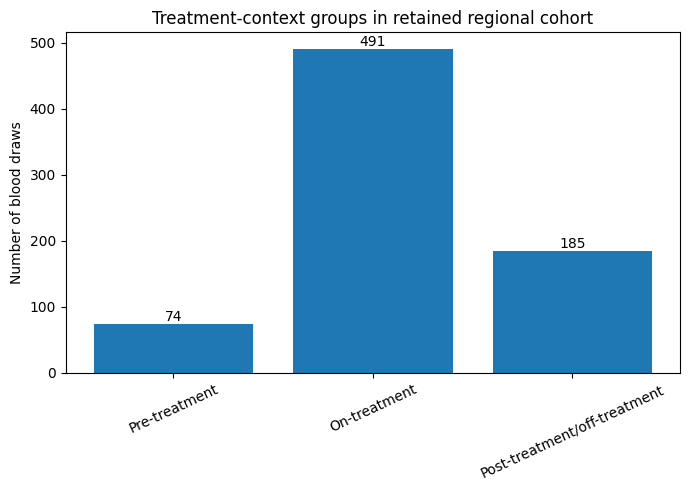

/scratch/slurm-10155642/ipykernel_678396/3235170171.py:253: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=TREATMENT_ORDER, showfliers=False)


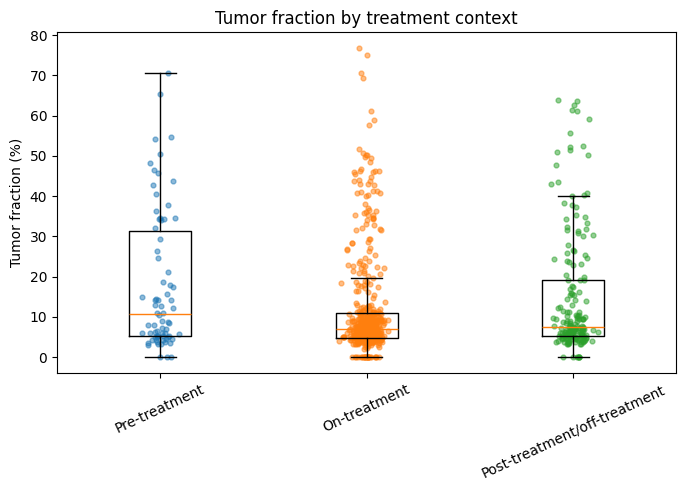

/scratch/slurm-10155642/ipykernel_678396/3235170171.py:253: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=TREATMENT_ORDER, showfliers=False)


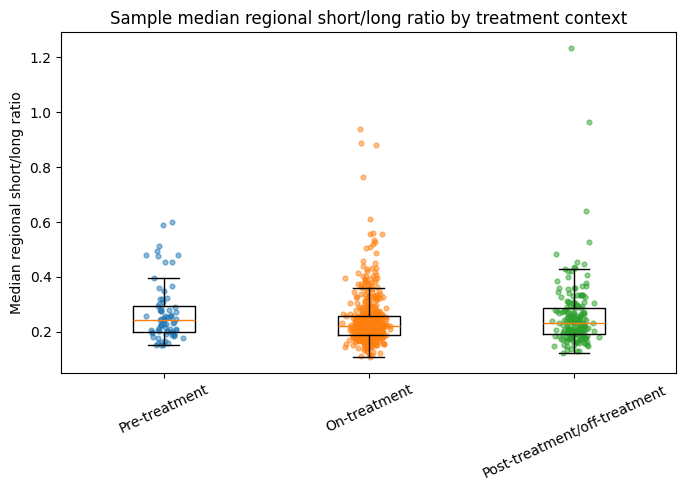

/scratch/slurm-10155642/ipykernel_678396/3235170171.py:253: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=TREATMENT_ORDER, showfliers=False)


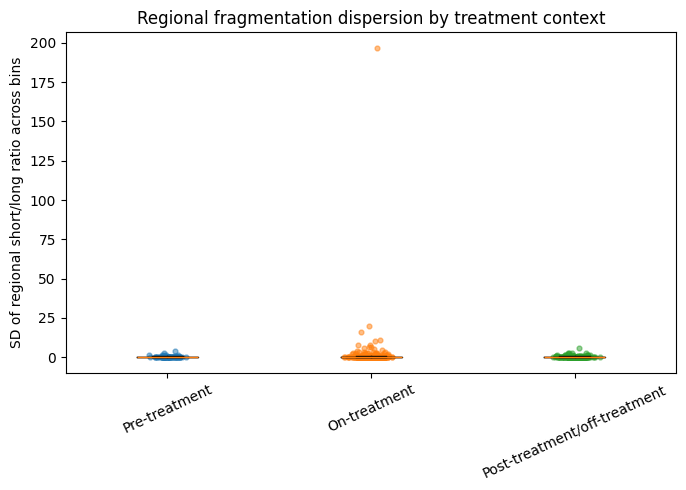

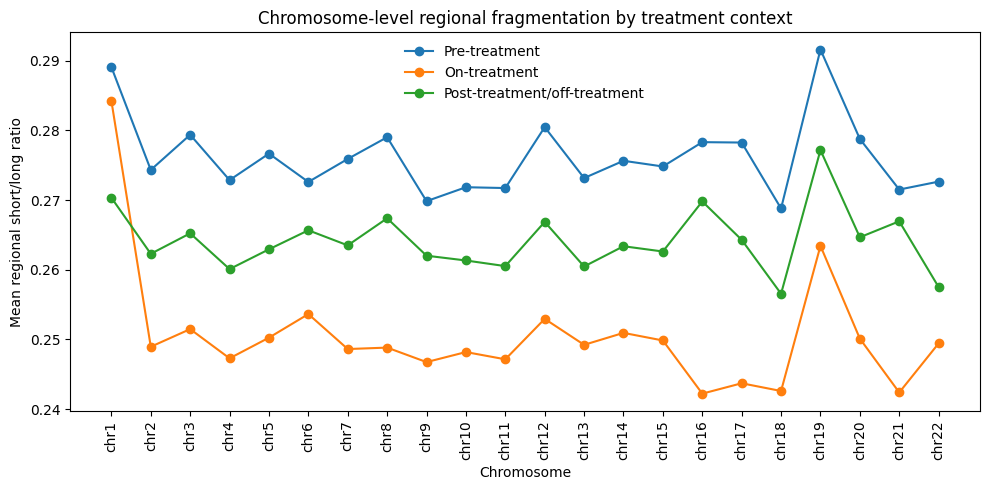

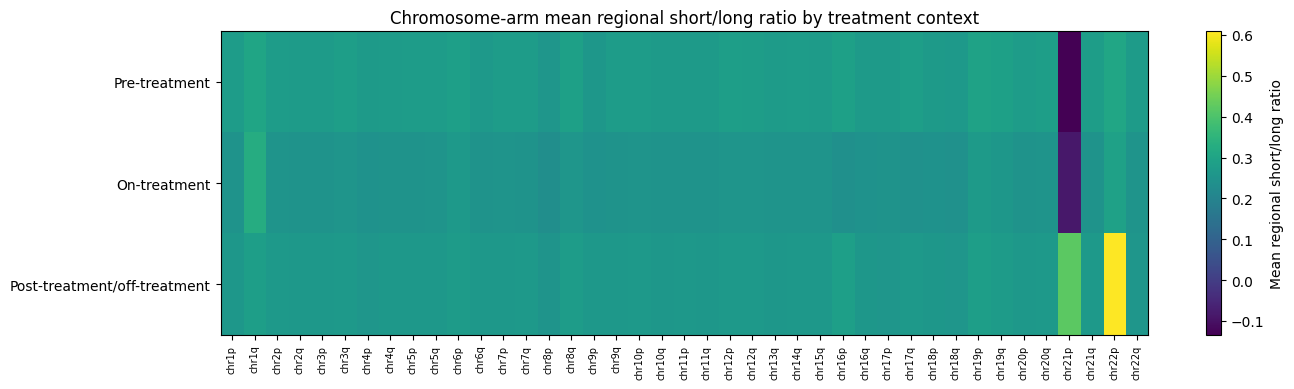

Plots saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_plots


In [11]:

# ============================================================
# STEP 8: Generate Step 1 QC plots
# ============================================================

save_barplot_counts(
    analysis_ready["Treatment_Context_3group"],
    PLOT_DIR / "01_treatment_context_counts_retained_samples.png",
    title="Treatment-context groups in retained regional cohort",
)

save_boxplot_by_context(
    sample_qc,
    TFX_COL,
    PLOT_DIR / "01_tumor_fraction_by_treatment_context.png",
    title="Tumor fraction by treatment context",
    ylabel="Tumor fraction (%)",
)

save_boxplot_by_context(
    sample_qc,
    "regional_median_short_long_ratio",
    PLOT_DIR / "01_sample_median_regional_short_long_ratio_by_treatment_context.png",
    title="Sample median regional short/long ratio by treatment context",
    ylabel="Median regional short/long ratio",
)

save_boxplot_by_context(
    sample_qc,
    "regional_sd_short_long_ratio",
    PLOT_DIR / "01_sample_regional_sd_by_treatment_context.png",
    title="Regional fragmentation dispersion by treatment context",
    ylabel="SD of regional short/long ratio across bins",
)

chrom_plot_df = chrom_matrix_out.copy()
chrom_cols = [
    c for c in chrom_plot_df.columns
    if str(c).startswith("chr") and c in chrom_matrix.columns
]

if len(chrom_cols) > 0:
    mean_chrom_by_context = (
        chrom_plot_df
        .groupby("Treatment_Context_3group", observed=False)[chrom_cols]
        .mean()
        .T
    )

    mean_chrom_by_context["chrom_order"] = [
        chrom_sort_key(c) for c in mean_chrom_by_context.index
    ]
    mean_chrom_by_context = mean_chrom_by_context.sort_values("chrom_order")
    mean_chrom_by_context = mean_chrom_by_context.drop(columns=["chrom_order"])

    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(mean_chrom_by_context.shape[0])

    for group in TREATMENT_ORDER:
        if group in mean_chrom_by_context.columns:
            ax.plot(x, mean_chrom_by_context[group].values, marker="o", label=group)

    ax.set_xticks(x)
    ax.set_xticklabels(mean_chrom_by_context.index, rotation=90)
    ax.set_xlabel("Chromosome")
    ax.set_ylabel("Mean regional short/long ratio")
    ax.set_title("Chromosome-level regional fragmentation by treatment context")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "01_chromosome_level_mean_by_treatment_context.png", dpi=300)
    plt.show()

arm_cols = [
    c for c in arm_matrix_out.columns
    if str(c).startswith("chr") and c in arm_matrix.columns
]

if len(arm_cols) > 0:
    arm_group_means = (
        arm_matrix_out
        .groupby("Treatment_Context_3group", observed=False)[arm_cols]
        .mean()
    )

    def arm_sort_key_for_plot(x):
        x = str(x)
        if x.endswith("p") or x.endswith("q"):
            return (chrom_sort_key(x[:-1]), x[-1])
        return (999, x)

    arm_order = sorted(arm_cols, key=arm_sort_key_for_plot)

    arm_group_means = arm_group_means.reindex(TREATMENT_ORDER)
    arm_group_means = arm_group_means[arm_order]

    fig, ax = plt.subplots(figsize=(14, 4))
    im = ax.imshow(arm_group_means.values, aspect="auto", interpolation="nearest")
    ax.set_yticks(np.arange(len(arm_group_means.index)))
    ax.set_yticklabels(arm_group_means.index)
    ax.set_xticks(np.arange(len(arm_order)))
    ax.set_xticklabels(arm_order, rotation=90, fontsize=7)
    ax.set_title("Chromosome-arm mean regional short/long ratio by treatment context")
    fig.colorbar(im, ax=ax, label="Mean regional short/long ratio")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "01_arm_level_group_mean_heatmap_by_treatment_context.png", dpi=300)
    plt.show()

print("Plots saved to:", PLOT_DIR)


In [12]:

# ============================================================
# STEP 9: Save Step 1 scientific notes
# ============================================================

notes = f"""
AURORA regional fragmentation Step 1 notes

Purpose:
This step prepares the regional fragmentation cohort for downstream statistical analysis.
It does not test treatment-context or tumor-fraction associations yet.

Key operations:
1. Loaded regional short/long ratio matrix.
2. Loaded Blood_draws clinical annotation.
3. Merged regional samples to clinical rows by Barcode.
4. Mapped treatment timing to three global-analysis groups:
   - Pre-treatment
   - On-treatment
   - Post-treatment/off-treatment
5. Grouped Between-treatment-lines with Post-treatment/off-treatment.
6. Excluded samples with missing or ambiguous treatment context.
7. Annotated each genomic bin using hg38 cytoband coordinates.
8. Created chromosome-level and chromosome-arm-level regional summaries.
9. Created both raw and sample-centered summary matrices.

Why sample-centered summaries are useful:
Raw regional short/long ratios retain both genome-wide and region-specific fragmentation shifts.
Sample-centered ratios subtract each sample's genome-wide median across bins, which helps focus
on regional redistribution beyond the sample's overall fragmentation level.

Why cytoband annotation is useful:
Cytoband annotation allows 100 kb bins to be summarized into chromosome arms such as chr1p and chr1q.
This provides a lower-dimensional regional analysis layer before high-dimensional bin-level modeling.

Important caution:
Step 1 is QC and feature construction only. Treatment or tumor-fraction associations should not be
claimed from these summary plots alone. Formal patient-clustered models will be performed in Step 2.

Output tables:
{TABLE_DIR}

Output plots:
{PLOT_DIR}
"""

notes_path = TABLE_DIR / "01_step1_scientific_notes.txt"

with open(notes_path, "w") as fh:
    fh.write(notes.strip() + "\n")

print(notes)
print("Saved notes:", notes_path)
print("Notebook completed:", time.ctime())



AURORA regional fragmentation Step 1 notes

Purpose:
This step prepares the regional fragmentation cohort for downstream statistical analysis.
It does not test treatment-context or tumor-fraction associations yet.

Key operations:
1. Loaded regional short/long ratio matrix.
2. Loaded Blood_draws clinical annotation.
3. Merged regional samples to clinical rows by Barcode.
4. Mapped treatment timing to three global-analysis groups:
   - Pre-treatment
   - On-treatment
   - Post-treatment/off-treatment
5. Grouped Between-treatment-lines with Post-treatment/off-treatment.
6. Excluded samples with missing or ambiguous treatment context.
7. Annotated each genomic bin using hg38 cytoband coordinates.
8. Created chromosome-level and chromosome-arm-level regional summaries.
9. Created both raw and sample-centered summary matrices.

Why sample-centered summaries are useful:
Raw regional short/long ratios retain both genome-wide and region-specific fragmentation shifts.
Sample-centered ratios su